<a href="https://colab.research.google.com/github/europecodingschool/ECS---VB---YZ---08.26/blob/main/VB_YZ_Ders_24_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import urllib.request

In [4]:
adres = "https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/"
urllib.request.urlretrieve(adres + "smarties.png", "smarties.png")

print("OpenCV sürümü", cv2.__version__)


OpenCV sürümü 5.0.0


In [8]:
img = cv2.imread("smarties.png")

print("Tip:", type(img))
print("Şekil:", img.shape)
print("Veri tipi:",img.dtype)
print("En küçük ve en büyük değer:", img.min(), img.max())


Tip: <class 'numpy.ndarray'>
Şekil: (356, 413, 3)
Veri tipi: uint8
En küçük ve en büyük değer: 0 255


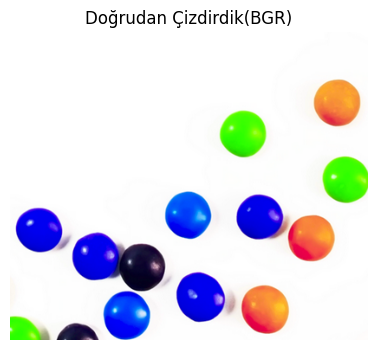

In [10]:
plt.figure(figsize=(10,4))
plt.imshow(img)
plt.title("Doğrudan Çizdirdik(BGR)")
plt.axis("off")
plt.show()

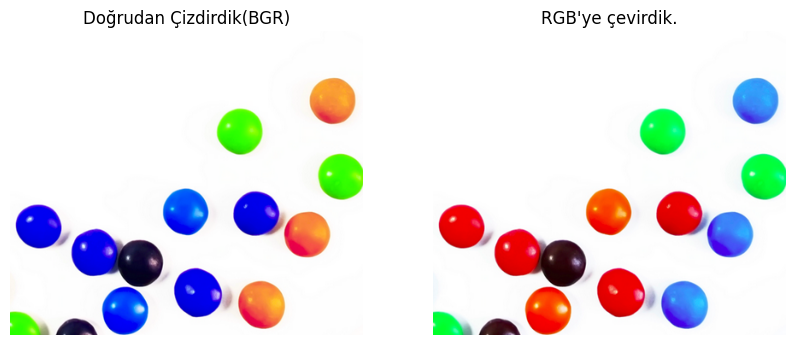

In [13]:
#Renk dönüşümü BGR > RGB

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.imshow(img)
plt.title("Doğrudan Çizdirdik(BGR)")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(img_rgb)
plt.title("RGB'ye çevirdik.")
plt.axis("off")
plt.show()

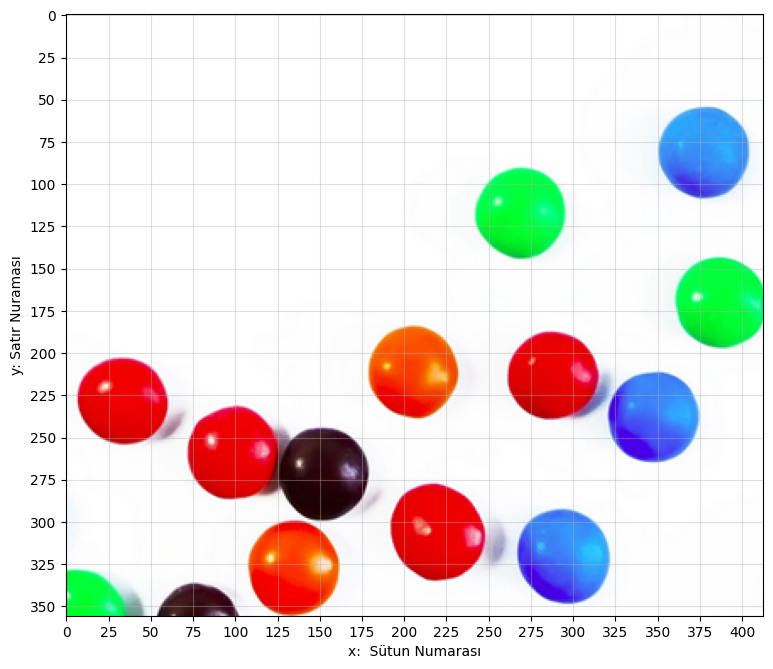

In [15]:
#EKSENLİ ÇİZİM - KOORDİNAT OKUMA

plt.figure(figsize=(9,8))
plt.imshow(img_rgb)
plt.xticks(range(0, 420, 25))
plt.yticks(range(0,360,25))
plt.xlabel("x:  Sütun Numarası")
plt.ylabel("y: Satır Nuraması")
plt.grid(alpha=0.4)
plt.show()

Gri Şekil: (356, 413)
Zemin: 255
Kırmızı şeker: 71
Yeşil şeker: 158
mavi şeker: 134


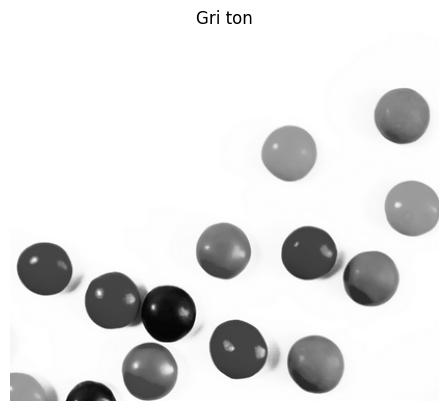

In [22]:
#GRİYE ÇEVİRME

gri = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

print("Gri Şekil:", gri.shape)
print("Zemin:", gri[0,0])
print("Kırmızı şeker:", gri[225,25])
print("Yeşil şeker:", gri[110,275])
print("mavi şeker:", gri[75,375])

plt.imshow(gri,cmap="gray")
plt.title("Gri ton")
plt.axis("off")
plt.show()

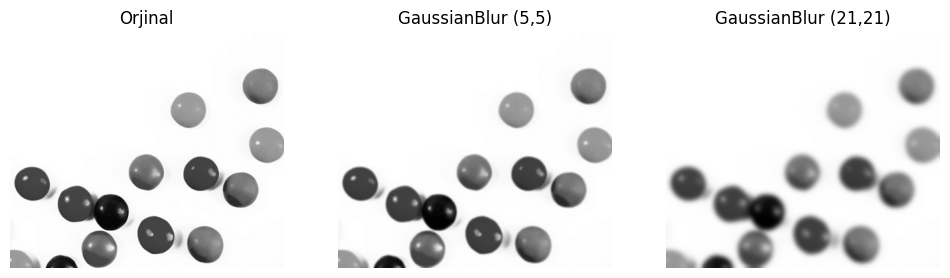

In [26]:
#BULANIKLAŞTIRMA - her görüntüde ufak tefek paratizler vardır. bunların yanıltmaması adına bir miktar bulanıklaştırmak gerekir.

bulanik = cv2.GaussianBlur(gri, (5,5), 0) # her pikselin yerine, çevresindeki küçük pencerenin ortalamasını koyuyor,

cok_bulanik = cv2.GaussianBlur(gri, (21,21), 0)

plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.imshow(gri,cmap="gray")
plt.title("Orjinal")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(bulanik,cmap="gray")
plt.title("GaussianBlur (5,5)")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(cok_bulanik,cmap="gray")
plt.title("GaussianBlur (21,21)")
plt.axis("off")

plt.show()

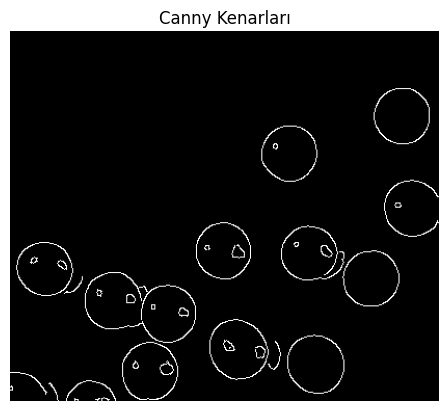

In [29]:
#KENARLARI BULMA - cv2.Canny

kenarlar = cv2.Canny(bulanik, 50, 150) # alt eşik ve üst eşik değeri parlaklık 50 den küçükse kenar değil, 150 den büyükse kesin kenar, genelde arlaarında 2 3 kat olur.

plt.imshow(kenarlar, cmap="gray")
plt.title("Canny Kenarları")
plt.axis("off")
plt.show()


In [31]:
#PARLAKLIKLA MASKE ÇIKARMA - Hangi parlaklık değerinde büyük (koyu) olana şeker diyeceğiz. bu sayıya eşik değeri denir. Eşiği tahmin etmiyoruz. OPEN CV Otsu yöntemi ile otmatik bulacağız.
# bizim fotoğrafımızda koyu şekerler ve açık zemin.


esik, maske = cv2.threshold(bulanik, 0,255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU) # Otsu eşiği sen bul. binary_inv = eşikten koyu pikseller 255, açıklar 0

print("Otsu'nun bulduğu eşik:", esik)

Otsu'nun bulduğu eşik: 177.0


THRESH_BINARY_INV - Eşikten büyük pikseller 0(siyah) - küçükler ve eşitler 255(beyaz) - koyu nesne açık zemin

THRESH_BINARY - Eşikten büyük pikseller 255(beyaz) - küçükler ve eşitler 0(siyah) - açık nesne - koyu zemin

/tmp/ipykernel_782/1557505639.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


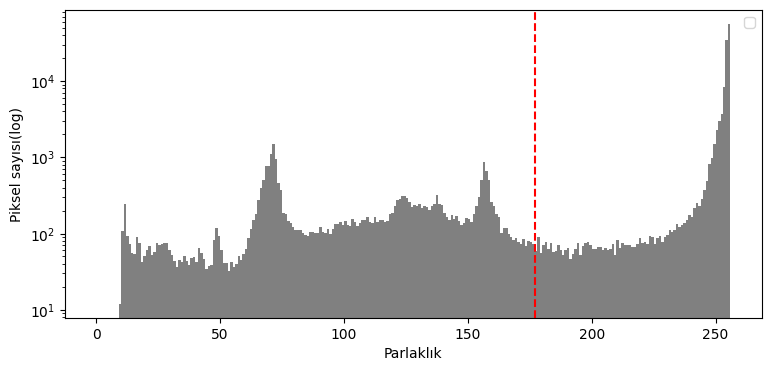

In [34]:
plt.figure(figsize=(9,4))

plt.hist(bulanik.ravel(), bins=256, range=(0,256), color="gray")
plt.yscale("log")
plt.axvline(esik, color="red", linestyle="--")
plt.xlabel("Parlaklık")
plt.ylabel("Piksel sayısı(log)")
plt.legend()
plt.show()

Maskedeki değerler: [  0 255]
Beyaz Piksel sayısı: 28968
Maske boyutu: (356, 413)


(np.float64(-0.5), np.float64(412.5), np.float64(355.5), np.float64(-0.5))

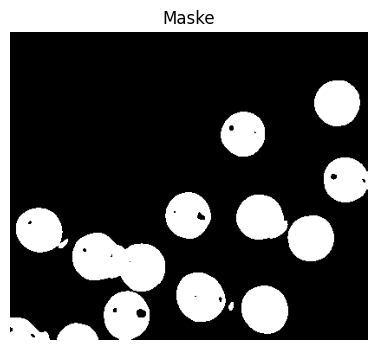

In [37]:
# MASKEYE BAKMAK

print("Maskedeki değerler:", np.unique(maske))
print("Beyaz Piksel sayısı:", cv2.countNonZero(maske))
print("Maske boyutu:", maske.shape)

plt.figure(figsize=(9,4))
plt.imshow(maske, cmap="gray")
plt.title("Maske")
plt.axis("off")

In [ ]:
# KONTUR BULMAK ve SAYMAK

